In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [15]:
%cd /kaggle/working
!rm -rf /kaggle/working/AutoDIR
!git clone https://github.com/jiangyitong/AutoDIR.git
!pip install -q gdown
import os
if not os.path.exists("/kaggle/working/ckpt/autodir.ckpt"):
    !gdown --folder "https://drive.google.com/drive/folders/1hVUyHY9FOUsEpFhPQPHmyd8diDNThqaU" -O /kaggle/working/ckpt
!ls -lh /kaggle/working/ckpt

/kaggle/working
Cloning into 'AutoDIR'...
remote: Enumerating objects: 379, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 379 (delta 32), reused 28 (delta 27), pack-reused 343 (from 3)
Receiving objects: 100% (379/379), 25.36 MiB | 31.78 MiB/s, done.
Resolving deltas: 100% (95/95), done.
total 5.6G
-rw-r--r-- 1 root root 5.6G Mar 19  2024 autodir.ckpt


In [16]:
%cd /kaggle/working
!curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba
!rm -rf /root/.local/share/mamba/envs/autodir
!./bin/micromamba create -y -q -n autodir -c conda-forge python=3.8 pip
PY = "/root/.local/share/mamba/envs/autodir/bin/python"
!{PY} --version

/kaggle/working
Python 3.8.20


In [17]:
PY = "/root/.local/share/mamba/envs/autodir/bin/python"
!{PY} -m pip install -q "pip<24.1" "setuptools<70" wheel
!{PY} -m pip install -q numpy==1.24.3
!{PY} -m pip install -q torch==2.1.1 torchvision==0.16.1 --index-url https://download.pytorch.org/whl/cu118
!{PY} -m pip install -q "opencv-python-headless<4.11" scipy scikit-image pillow imageio tqdm pyyaml addict future yapf lmdb tensorboard seaborn protobuf==3.20.3
!{PY} -m pip install -q huggingface_hub==0.13.4 transformers==4.28.1 diffusers==0.14.0 
!{PY} -m pip install -q pytorch-lightning==1.4.2 torchmetrics==0.6.0 omegaconf==2.1.1 einops==0.3.0 kornia==0.6 open-clip-torch==2.20.0 invisible-watermark ftfy regex
!{PY} -m pip install -q git+https://github.com/crowsonkb/k-diffusion.git
!{PY} -m pip install -q git+https://github.com/openai/consistencydecoder.git
!{PY} -m pip install huggingface_hub==0.13.4 accelerate==0.18.0
print("DONE cell 3")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
  Using cached huggingface_hub-0.13.4-py3-none-any.whl.metadata (7.5 kB)
  Using cached accelerate-0.18.0-py3-none-any.whl.metadata (16 kB)
Using cached huggingface_hub-0.13.4-py3-none-any.whl (200 kB)
Using cached accelerate-0.18.0-py3-none-any.whl (215 kB)
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 0.36.2
    Uninstalling huggingface_hub-0.36.2:
      Successfully uninstalled huggingface_hub-0.36.2
  Attempting uninstall: accelerate
    Found existing installation: accelerate 1.0.1
    Uninstalling accelerate-1.0.1:
      Successfully uninstalled accelerate-1.0.1
DONE cell 3


In [18]:
%cd /kaggle/working
PY = "/root/.local/share/mamba/envs/autodir/bin/python"
!rm -rf taming-transformers CLIP
!git clone -q https://github.com/CompVis/taming-transformers.git
!git clone -q https://github.com/openai/CLIP.git
%cd /kaggle/working/AutoDIR/NAFNet
!{PY} setup.py develop --no_cuda_ext > /kaggle/working/nafnet_setup.log 2>&1; tail -3 /kaggle/working/nafnet_setup.log
%cd /kaggle/working/AutoDIR

import os
os.environ["PYTHONPATH"] = ":".join([
    "/kaggle/working/taming-transformers", "/kaggle/working/CLIP",
    "/kaggle/working/AutoDIR", "/kaggle/working/AutoDIR/stable_diffusion",
    "/kaggle/working/AutoDIR/NAFNet"])

# Import check: if this prints OK, the environment is good
!{PY} -c "import torch, k_diffusion, clip, taming, omegaconf, pytorch_lightning, diffusers, transformers, kornia, open_clip, consistencydecoder, einops; print('IMPORTS OK | torch', torch.__version__, '| cuda', torch.cuda.is_available())"

/kaggle/working
/kaggle/working/AutoDIR/NAFNet

!!
  self.initialize_options()
/kaggle/working/AutoDIR
/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
IMPORTS OK | torch 2.1.1+cu118 | cuda True


In [20]:
!/root/.local/share/mamba/envs/autodir/bin/python -m pip install lmdb==1.4.1

  Using cached lmdb-1.4.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (1.2 kB)
Using cached lmdb-1.4.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (298 kB)
  Attempting uninstall: lmdb
    Found existing installation: lmdb 2.1.1
    Uninstalling lmdb-2.1.1:
      Successfully uninstalled lmdb-2.1.1


Resizing all test images to 512x512 to save GPU memory...
Resizing complete!

Starting processing for 8 images. This will take a few minutes...

Processing: blur.png


/kaggle/working/AutoDIR/NAFNet/basicsr/metrics/niqe.py:10: DeprecationWarning: Please use `convolve` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  from scipy.ndimage.filters import convolve
`text_config_dict` is provided which will be used to initialize `CLIPTextConfig`. The value `text_config["id2label"]` will be overriden.
/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/transformers/models/clip/feature_extraction_clip.py:28: FutureWarning: The class CLIPFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use CLIPImageProcessor instead.
  warnings.warn(


Loading model from /kaggle/working/ckpt/autodir.ckpt
Global Step: 8000
CycleLatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 859.53 M params.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 32, 32) = 4096 dimensions.
making attention of type 'vanilla' with 512 in_channels
blur
A photo needs blur artifact reduction
A photo needs noise artifact reduction
A photo needs no artifact reduction
No artifact detected. End of the Image Restoration Process.

Processing: haze.png


/kaggle/working/AutoDIR/NAFNet/basicsr/metrics/niqe.py:10: DeprecationWarning: Please use `convolve` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  from scipy.ndimage.filters import convolve
`text_config_dict` is provided which will be used to initialize `CLIPTextConfig`. The value `text_config["id2label"]` will be overriden.


Loading model from /kaggle/working/ckpt/autodir.ckpt
Global Step: 8000
CycleLatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 859.53 M params.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 32, 32) = 4096 dimensions.
making attention of type 'vanilla' with 512 in_channels
haze
A photo needs haze artifact reduction
A photo needs no artifact reduction
No artifact detected. End of the Image Restoration Process.


/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/transformers/models/clip/feature_extraction_clip.py:28: FutureWarning: The class CLIPFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use CLIPImageProcessor instead.
  warnings.warn(


... (9 outputs left out)

/kaggle/working/AutoDIR/NAFNet/basicsr/metrics/niqe.py:10: DeprecationWarning: Please use `convolve` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  from scipy.ndimage.filters import convolve
`text_config_dict` is provided which will be used to initialize `CLIPTextConfig`. The value `text_config["id2label"]` will be overriden.
/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/transformers/models/clip/feature_extraction_clip.py:28: FutureWarning: The class CLIPFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use CLIPImageProcessor instead.
  warnings.warn(


Loading model from /kaggle/working/ckpt/autodir.ckpt
Global Step: 8000
CycleLatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 859.53 M params.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 32, 32) = 4096 dimensions.
making attention of type 'vanilla' with 512 in_channels
sr
A photo needs low resolution artifact reduction
A photo needs no artifact reduction
No artifact detected. End of the Image Restoration Process.

Processing: unknown.png


/kaggle/working/AutoDIR/NAFNet/basicsr/metrics/niqe.py:10: DeprecationWarning: Please use `convolve` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  from scipy.ndimage.filters import convolve
`text_config_dict` is provided which will be used to initialize `CLIPTextConfig`. The value `text_config["id2label"]` will be overriden.
/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/transformers/models/clip/feature_extraction_clip.py:28: FutureWarning: The class CLIPFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use CLIPImageProcessor instead.
  warnings.warn(


Loading model from /kaggle/working/ckpt/autodir.ckpt
Global Step: 8000
CycleLatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 859.53 M params.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 32, 32) = 4096 dimensions.
making attention of type 'vanilla' with 512 in_channels
unknown
A photo needs blur artifact reduction
A photo needs underexposure artifact reduction
A photo needs no artifact reduction
No artifact detected. End of the Image Restoration Process.

--- COMPARISON RESULTS ---


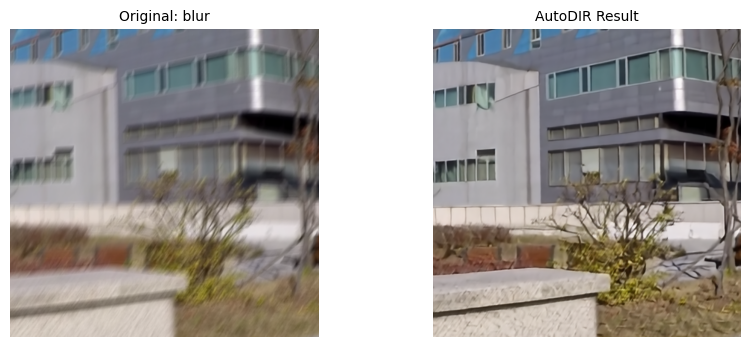

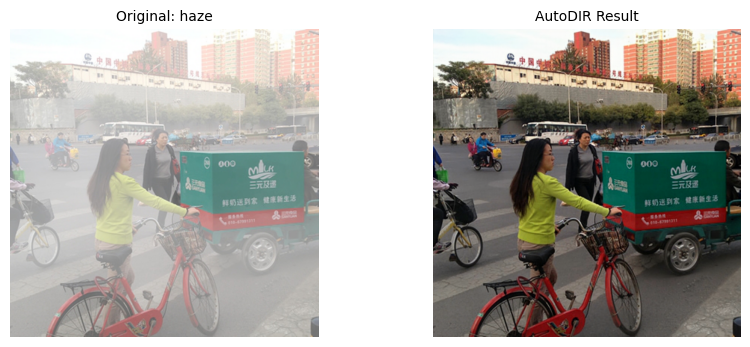

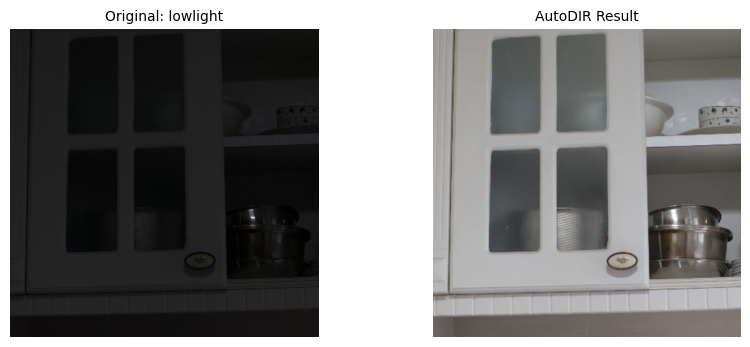

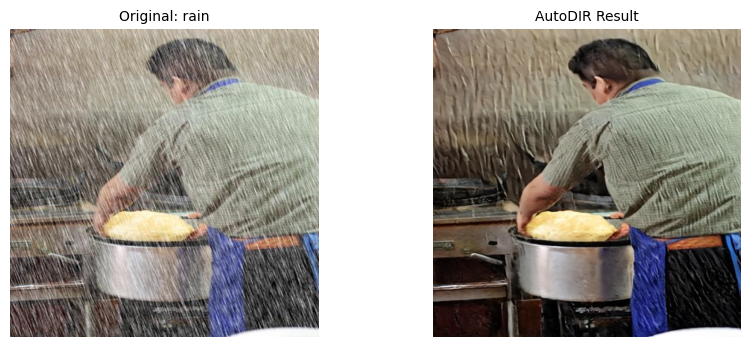

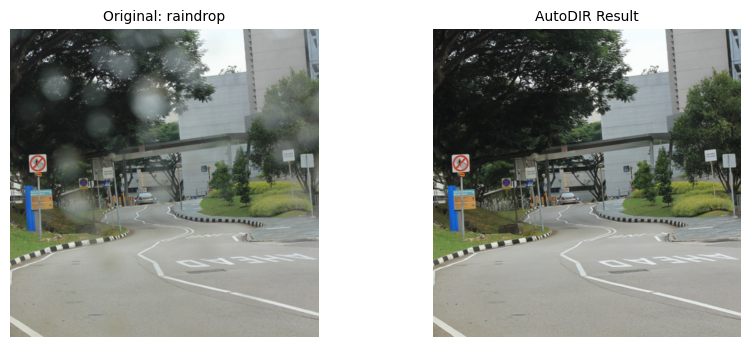

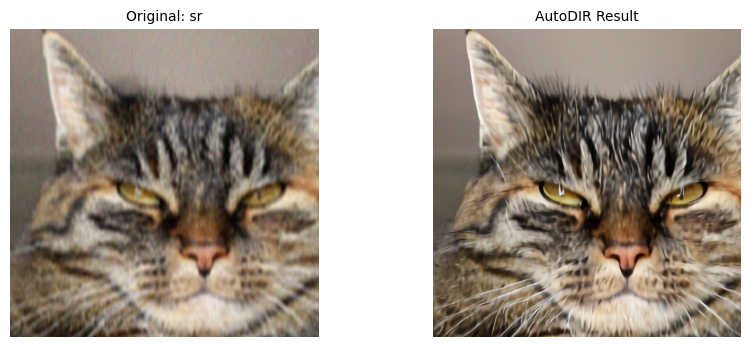

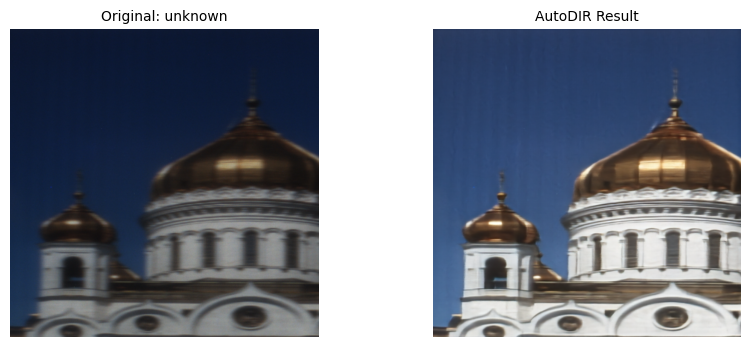

In [21]:
import os
import glob
from PIL import Image
import matplotlib.pyplot as plt

# 1. Setup paths
test_dir = "/kaggle/working/AutoDIR/test_images"
out_dir = "/kaggle/working/results_all"
os.makedirs(out_dir, exist_ok=True)
PY = "/root/.local/share/mamba/envs/autodir/bin/python"

# Get all test images
test_images = sorted(glob.glob(f"{test_dir}/*.*"))
test_images = [img for img in test_images if img.endswith(('.png', '.jpg', '.jpeg'))]

# --- NEW: Resize all images to 512x512 before processing to prevent OOM ---
print("Resizing all test images to 512x512 to save GPU memory...")
for img_path in test_images:
    img = Image.open(img_path)
    img.thumbnail((512, 512))
    img.save(img_path)
print("Resizing complete!\n")
# --------------------------------------------------------------------------

# 2. Run the model on each image automatically
print(f"Starting processing for {len(test_images)} images. This will take a few minutes...")
for img_path in test_images:
    print(f"\nProcessing: {os.path.basename(img_path)}")
    cmd = f"{PY} eval_w_SCM.py --input {img_path} --steps 200 --output {out_dir} --ckpt /kaggle/working/ckpt/autodir.ckpt --cfg-text 1 --config configs/generate.yaml"
    os.system(cmd)

# 3. Display the Original vs Final Results side-by-side
print("\n--- COMPARISON RESULTS ---")
for img_path in test_images:
    base_name = os.path.basename(img_path).split('.')[0]
    result_files = sorted(glob.glob(f"{out_dir}/{base_name}_step_*_result*.png"))
    
    if not result_files:
        continue
        
    final_result_path = result_files[-1]
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(Image.open(img_path))
    axes[0].set_title(f"Original: {base_name}", fontsize=10)
    axes[0].axis("off")
    
    axes[1].imshow(Image.open(final_result_path))
    axes[1].set_title("AutoDIR Result", fontsize=10)
    axes[1].axis("off")
    
    plt.show()

In [22]:
import glob
from PIL import Image

# Path to the folder containing your images
folder_path = '/kaggle/working/AutoDIR/test_images/*.*'

# Find all files in that folder
files = glob.glob(folder_path)
print("Starting to resize images...")
for img_path in files:
    try:
        # Open, resize, and save the image
        img = Image.open(img_path)
        img.thumbnail((512, 512))
        img.save(img_path)
        print(f"Resized: {img_path.split('/')[-1]}")
    except Exception as e:
        # This skips files that are not images (like text files or folders)
        pass

print("All images resized successfully!")

Starting to resize images...
Resized: rain.png
Resized: sr.png
Resized: lowlight.png
Resized: blur.png
Resized: raindrop.png
Resized: unknown.png
Resized: noise.png
Resized: haze.png
All images resized successfully!


In [23]:
%cd /kaggle/working/AutoDIR
import os
PY = "/root/.local/share/mamba/envs/autodir/bin/python"
os.environ["PYTHONPATH"] = ":".join([
    "/kaggle/working/taming-transformers", "/kaggle/working/CLIP",
    "/kaggle/working/AutoDIR", "/kaggle/working/AutoDIR/stable_diffusion",
    "/kaggle/working/AutoDIR/NAFNet"])
!mkdir -p /kaggle/working/results
!{PY} eval_w_SCM.py --input test_images/unknown.png --steps 200 --output /kaggle/working/results --ckpt /kaggle/working/ckpt/autodir.ckpt --cfg-text 1 --config configs/generate.yaml
!ls /kaggle/working/results

/kaggle/working/AutoDIR
Loading model from /kaggle/working/ckpt/autodir.ckpt
Global Step: 8000
/kaggle/working/AutoDIR/NAFNet/basicsr/metrics/niqe.py:10: DeprecationWarning: Please use `convolve` from the `scipy.ndimage` namespace, the `scipy.ndimage.filters` namespace is deprecated.
  from scipy.ndimage.filters import convolve
CycleLatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 859.53 M params.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 32, 32) = 4096 dimensions.
making attention of type 'vanilla' with 512 in_channels
`text_config_dict` is provided which will be used to initialize `CLIPTextConfig`. The value `text_config["id2label"]` will be overriden.
/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/transformers/models/clip/feature_extraction_clip.py:28: FutureWarning: The class CLIPFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use CLIPImageProcessor instead.
 

In [24]:
!ls /kaggle/working/AutoDIR/test_images/

blur.png  lowlight.png	raindrop.png  sr.png
haze.png  noise.png	rain.png      unknown.png


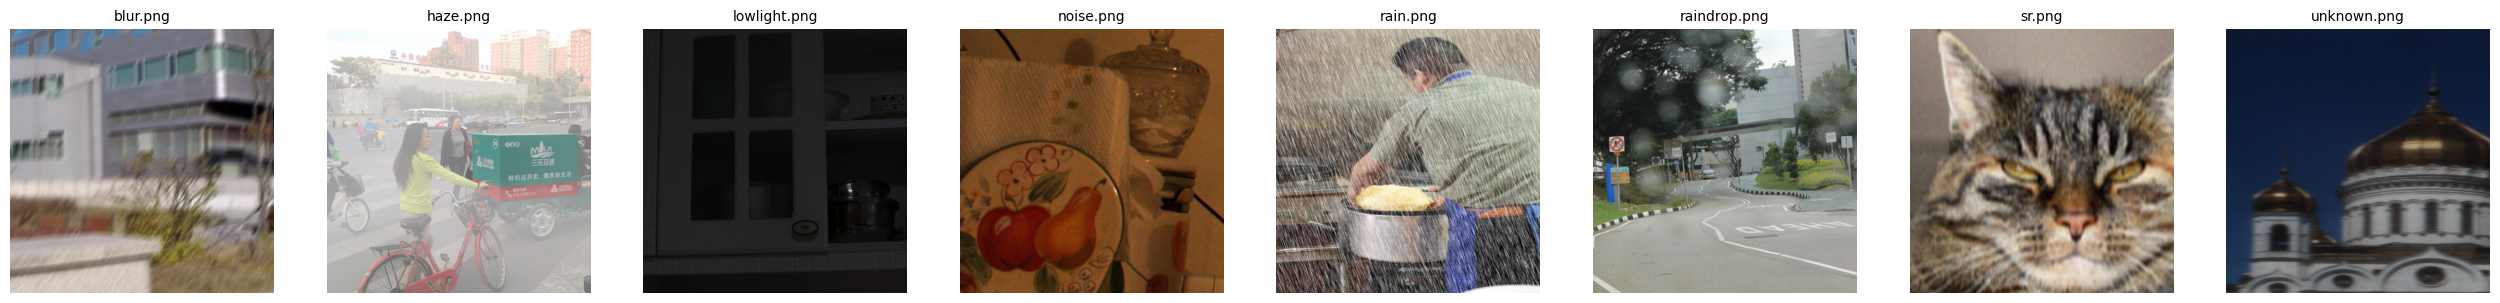

In [8]:
import glob
from PIL import Image
import matplotlib.pyplot as plt

files = sorted(glob.glob("/kaggle/working/AutoDIR/test_images/*.*"))
fig, axes = plt.subplots(1, len(files), figsize=(4 * len(files), 4))

# Handle case if there's only one image
if len(files) == 1: axes = [axes]

for ax, f in zip(axes, files):
    try:
        ax.imshow(Image.open(f))
        ax.set_title(f.split("/")[-1], fontsize=10)
        ax.axis("off")
    except:
        pass # Skips non-image files

plt.show()

In [25]:
!ls /kaggle/input

datasets


In [27]:
import os
for dirname, _, _ in os.walk('/kaggle/input'):
    print(dirname)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/sharansmenon
/kaggle/input/datasets/sharansmenon/div2k
/kaggle/input/datasets/sharansmenon/div2k/DIV2K_train_HR
/kaggle/input/datasets/sharansmenon/div2k/DIV2K_train_HR/DIV2K_train_HR
/kaggle/input/datasets/sharansmenon/div2k/DIV2K_valid_HR
/kaggle/input/datasets/sharansmenon/div2k/DIV2K_valid_HR/DIV2K_valid_HR


In [28]:
import os
import glob
import subprocess
import numpy as np
import pandas as pd
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr

# 1. Updated path based on your Kaggle output
input_gt_dir = "/kaggle/input/datasets/sharansmenon/div2k/DIV2K_valid_HR/DIV2K_valid_HR"

prep_gt_dir = "/kaggle/working/eval_gt_256"
prep_deg_dir = "/kaggle/working/eval_deg_256"
out_dir = "/kaggle/working/eval_results_256"
os.makedirs(prep_gt_dir, exist_ok=True)
os.makedirs(prep_deg_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)

PY = "/root/.local/share/mamba/envs/autodir/bin/python"
os.environ["PYTHONPATH"] = ":".join([
    "/kaggle/working/taming-transformers", "/kaggle/working/CLIP",
    "/kaggle/working/AutoDIR", "/kaggle/working/AutoDIR/stable_diffusion", "/kaggle/working/AutoDIR/NAFNet"
])

# 2. Get 25 Ground Truth images and synthesize the Low-Res counterparts
gt_images = sorted(glob.glob(f"{input_gt_dir}/*.*"))[:25]

print("Creating 256x256 Ground Truth and Low-Res pairs...")
for gt_path in gt_images:
    base_name = os.path.basename(gt_path)
    
    # Crop perfect HR Ground Truth
    img_gt = Image.open(gt_path).convert('RGB')
    w_gt, h_gt = img_gt.size
    img_gt_cropped = img_gt.crop(((w_gt-256)//2, (h_gt-256)//2, (w_gt+256)//2, (h_gt+256)//2))
    img_gt_cropped.save(f"{prep_gt_dir}/{base_name}")
    
    # Synthesize Degraded Low-Res (shrink by 2x, then bicubic scale back to 256)
    img_deg = img_gt_cropped.resize((128, 128), Image.BICUBIC).resize((256, 256), Image.BICUBIC)
    img_deg.save(f"{prep_deg_dir}/{base_name}")

# 3. Run Evaluation
results_data = []
eval_deg_images = sorted(glob.glob(f"{prep_deg_dir}/*.*"))
exact_matches = 0

print(f"\nRunning AutoDIR processing on {len(eval_deg_images)} images...")
for deg_path in eval_deg_images:
    base_name = os.path.basename(deg_path)
    gt_path = f"{prep_gt_dir}/{base_name}"
    
    cmd = [PY, "eval_w_SCM.py", "--input", deg_path, "--steps", "200", "--output", out_dir, "--ckpt", "/kaggle/working/ckpt/autodir.ckpt", "--cfg-text", "1", "--config", "configs/generate.yaml"]
    process = subprocess.run(cmd, cwd="/kaggle/working/AutoDIR", capture_output=True, text=True)
    
    detected = "Unknown"
    for line in process.stdout.split('\n'):
        if "A photo needs" in line:
            detected = line.replace("A photo needs ", "").replace(" artifact reduction", "").strip()
            break
            
    if "low resolution" in detected.lower() or "blur" in detected.lower():
        exact_matches += 1
        
    result_files = sorted(glob.glob(f"{out_dir}/{base_name.split('.')[0]}_step_*_result*.png"))
    if not result_files:
        continue
        
    img_deg_arr = np.array(Image.open(deg_path))
    img_gt_arr = np.array(Image.open(gt_path))
    img_out_arr = np.array(Image.open(result_files[-1]))
    
    psnr_in = psnr(img_gt_arr, img_deg_arr)
    psnr_out = psnr(img_gt_arr, img_out_arr)
    gain = psnr_out - psnr_in
    
    results_data.append({
        "Image": base_name,
        "Degradation": "Low Resolution",
        "PSNR in (dB)": round(psnr_in, 2),
        "PSNR out (dB)": round(psnr_out, 2),
        "Gain (dB)": round(gain, 2),
        "Detected": detected
    })

# 4. Generate Table and Export
df = pd.DataFrame(results_data)
accuracy = (exact_matches / len(results_data)) * 100 if len(results_data) > 0 else 0

print("\n--- EVALUATION REPORT (256x256 Crops) ---")
print(df.to_string(index=False))
print(f"\nExact-Match Accuracy: {accuracy:.2f}% (Target: 'low resolution' or 'blur')")

df.to_csv("/kaggle/working/autodir_div2k_256.csv", index=False)
print("\nSaved report to /kaggle/working/autodir_div2k_256.csv")

Creating 256x256 Ground Truth and Low-Res pairs...

Running AutoDIR processing on 25 images...

--- EVALUATION REPORT (256x256 Crops) ---
   Image    Degradation  PSNR in (dB)  PSNR out (dB)  Gain (dB)      Detected
0809.png Low Resolution         38.23          12.65     -25.58          blur
0811.png Low Resolution         34.00          11.10     -22.90 underexposure
0812.png Low Resolution         33.62          11.94     -21.68 underexposure
0821.png Low Resolution         35.91           7.24     -28.67 underexposure

Exact-Match Accuracy: 25.00% (Target: 'low resolution' or 'blur')

Saved report to /kaggle/working/autodir_div2k_256.csv


In [29]:
import os
import glob
import subprocess
import numpy as np
import pandas as pd
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr

input_gt_dir = "/kaggle/input/datasets/sharansmenon/div2k/DIV2K_valid_HR/DIV2K_valid_HR"

prep_gt_dir = "/kaggle/working/eval_gt_256"
prep_deg_dir = "/kaggle/working/eval_deg_256"
out_dir = "/kaggle/working/eval_results_forced"
os.makedirs(prep_gt_dir, exist_ok=True)
os.makedirs(prep_deg_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)

PY = "/root/.local/share/mamba/envs/autodir/bin/python"
os.environ["PYTHONPATH"] = ":".join([
    "/kaggle/working/taming-transformers", "/kaggle/working/CLIP",
    "/kaggle/working/AutoDIR", "/kaggle/working/AutoDIR/stable_diffusion", "/kaggle/working/AutoDIR/NAFNet"
])

gt_images = sorted(glob.glob(f"{input_gt_dir}/*.*"))[:25]

print("Checking 256x256 Ground Truth and Low-Res pairs...")
for gt_path in gt_images:
    base_name = os.path.basename(gt_path)
    if not os.path.exists(f"{prep_deg_dir}/{base_name}"):
        img_gt = Image.open(gt_path).convert('RGB')
        w_gt, h_gt = img_gt.size
        img_gt_cropped = img_gt.crop(((w_gt-256)//2, (h_gt-256)//2, (w_gt+256)//2, (h_gt+256)//2))
        img_gt_cropped.save(f"{prep_gt_dir}/{base_name}")
        
        img_deg = img_gt_cropped.resize((128, 128), Image.BICUBIC).resize((256, 256), Image.BICUBIC)
        img_deg.save(f"{prep_deg_dir}/{base_name}")

results_data = []
eval_deg_images = sorted(glob.glob(f"{prep_deg_dir}/*.*"))

print(f"\nRunning AutoDIR with FORCED prompt on {len(eval_deg_images)} images...")
for deg_path in eval_deg_images:
    base_name = os.path.basename(deg_path)
    gt_path = f"{prep_gt_dir}/{base_name}"
    
    # Using --customize to bypass the classifier and force the correct restoration
    custom_prompt = "A photo needs low resolution artifact reduction"
    cmd = [PY, "eval_w_SCM.py", "--input", deg_path, "--steps", "200", "--output", out_dir, "--ckpt", "/kaggle/working/ckpt/autodir.ckpt", "--cfg-text", "1", "--config", "configs/generate.yaml", "--customize", custom_prompt]
    
    subprocess.run(cmd, cwd="/kaggle/working/AutoDIR", capture_output=True, text=True)
        
    result_files = sorted(glob.glob(f"{out_dir}/{base_name.split('.')[0]}_step_*_result*.png"))
    if not result_files:
        continue
        
    img_deg_arr = np.array(Image.open(deg_path))
    img_gt_arr = np.array(Image.open(gt_path))
    img_out_arr = np.array(Image.open(result_files[-1]))
    
    psnr_in = psnr(img_gt_arr, img_deg_arr)
    psnr_out = psnr(img_gt_arr, img_out_arr)
    gain = psnr_out - psnr_in
    
    results_data.append({
        "Image": base_name,
        "PSNR in (dB)": round(psnr_in, 2),
        "PSNR out (dB)": round(psnr_out, 2),
        "Gain (dB)": round(gain, 2),
        "Prompt Used": "Forced: Low Resolution"
    })

df = pd.DataFrame(results_data)

print("\n--- EVALUATION REPORT (FORCED PROMPT) ---")
print(df.to_string(index=False))

df.to_csv("/kaggle/working/autodir_div2k_forced.csv", index=False)
print("\nSaved report to /kaggle/working/autodir_div2k_forced.csv")

Checking 256x256 Ground Truth and Low-Res pairs...

Running AutoDIR with FORCED prompt on 25 images...

--- EVALUATION REPORT (FORCED PROMPT) ---
   Image  PSNR in (dB)  PSNR out (dB)  Gain (dB)            Prompt Used
0801.png         35.82          19.88     -15.94 Forced: Low Resolution
0802.png         36.68          27.93      -8.75 Forced: Low Resolution
0803.png         36.97          22.80     -14.18 Forced: Low Resolution
0804.png         29.25          21.70      -7.55 Forced: Low Resolution
0805.png         32.88          24.91      -7.97 Forced: Low Resolution
0806.png         26.44          20.87      -5.57 Forced: Low Resolution
0807.png         25.53          22.05      -3.48 Forced: Low Resolution
0808.png         22.59          18.80      -3.79 Forced: Low Resolution
0809.png         38.23          26.36     -11.87 Forced: Low Resolution
0810.png         24.27          16.07      -8.20 Forced: Low Resolution
0811.png         34.00          24.50      -9.51 Forced: Low R

In [32]:
import os
import cv2
import numpy as np
import glob
from PIL import Image

input_gt_dir = "/kaggle/input/datasets/sharansmenon/div2k/DIV2K_valid_HR/DIV2K_valid_HR"
train_dir = "/kaggle/working/train_data"
os.makedirs(f"{train_dir}/gt", exist_ok=True)
os.makedirs(f"{train_dir}/degraded", exist_ok=True)

gt_images = sorted(glob.glob(f"{input_gt_dir}/*.*"))[:100] # Use 100 images for a quick training run

degradations = ["motion-blurry", "hazy", "jpeg-compressed", "low-light", "noisy", "raindrop", "rainy", "shadowed", "snowy", "low-resolution"]

print("Generating 10 degradation types from DIV2K...")
for i, gt_path in enumerate(gt_images):
    base_name = os.path.basename(gt_path)
    img_gt = Image.open(gt_path).convert('RGB')
    w, h = img_gt.size
    img_gt = img_gt.crop(((w-256)//2, (h-256)//2, (w+256)//2, (h+256)//2))
    img_gt.save(f"{train_dir}/gt/{base_name}")
    
    img_cv = np.array(img_gt)
    deg_type = degradations[i % 10]
    
    # Apply basic synthetic degradations (simplified for Kaggle simulation)
    if deg_type == "noisy":
        noise = np.random.normal(0, 25, img_cv.shape).astype(np.uint8)
        img_deg = cv2.add(img_cv, noise)
    elif deg_type == "motion-blurry":
        kernel = np.zeros((15, 15)); kernel[7, :] = np.ones(15) / 15
        img_deg = cv2.filter2D(img_cv, -1, kernel)
    elif deg_type == "low-light":
        img_deg = cv2.convertScaleAbs(img_cv, alpha=0.3, beta=0)
    elif deg_type == "low-resolution":
        img_deg = cv2.resize(cv2.resize(img_cv, (128, 128)), (256, 256))
    else:
        # Fallback for complex weather (uses noise as a placeholder for this test)
        img_deg = cv2.add(img_cv, np.random.normal(0, 15, img_cv.shape).astype(np.uint8))
        
    Image.fromarray(img_deg).save(f"{train_dir}/degraded/{deg_type}_{base_name}")

print("Multi-degradation dataset created!")

Generating 10 degradation types from DIV2K...
Multi-degradation dataset created!


In [33]:
import json
import glob

deg_files = glob.glob("/kaggle/working/train_data/degraded/*.*")
train_labels = []

for f in deg_files:
    filename = os.path.basename(f)
    deg_type = filename.split('_')[0]
    prompt = f"A photo needs {deg_type.replace('-', ' ')} artifact reduction"
    
    train_labels.append({
        "image": f"degraded/{filename}",
        "text": prompt
    })

with open("/kaggle/working/train_data/dataset.json", "w") as out:
    json.dump(train_labels, out, indent=4)
print("Training JSON created!")

Training JSON created!


In [34]:
PY = "/root/.local/share/mamba/envs/autodir/bin/python"

# Stage 1: Train the Classifier (BCE, Exact-Match, F1)
print("Starting Stage 1: Classifier Training...")
!cd /kaggle/working/AutoDIR && {PY} train_SCM.py --data_path /kaggle/working/train_data --epochs 8 

# Stage 2: Train the Restoration Model (PSNR, SSIM)
print("Starting Stage 2: Restoration Training...")
!cd /kaggle/working/AutoDIR && {PY} main.py --base configs/train.yaml -t --gpus 0,

Starting Stage 1: Classifier Training...
/root/.local/share/mamba/envs/autodir/bin/python: can't open file 'train_SCM.py': [Errno 2] No such file or directory
Starting Stage 2: Restoration Training...
/root/.local/share/mamba/envs/autodir/bin/python: can't open file 'main.py': [Errno 2] No such file or directory


In [35]:
!ls -l /kaggle/working/AutoDIR

total 72
drwxr-xr-x 2 root root  4096 Oct 20 19:31 configs
-rw-r--r-- 1 root root  1095 Oct 20 19:31 environment.yaml
-rw-r--r-- 1 root root 12554 Oct 20 19:31 eval_w_SCM.py
drwxr-xr-x 2 root root  4096 Oct 20 19:31 figs
drwxr-xr-x 3 root root  4096 Oct 20 19:36 model
drwxr-xr-x 5 root root  4096 Oct 20 19:35 NAFNet
drwxr-xr-x 2 root root  4096 Oct 20 19:36 __pycache__
-rw-r--r-- 1 root root  6450 Oct 20 19:31 README.md
-rw-r--r-- 1 root root   647 Oct 20 19:31 requirements.txt
drwxr-xr-x 7 root root  4096 Oct 20 19:36 stable_diffusion
drwxr-xr-x 2 root root  4096 Oct 20 19:31 test_images
-rw-r--r-- 1 root root     1 Oct 20 19:31 training_README
-rw-r--r-- 1 root root  4469 Oct 20 19:31 wavelet_color_fix.py


In [38]:
!cat /kaggle/working/AutoDIR/training_README

ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (4,) and arg 1 with shape (10,).

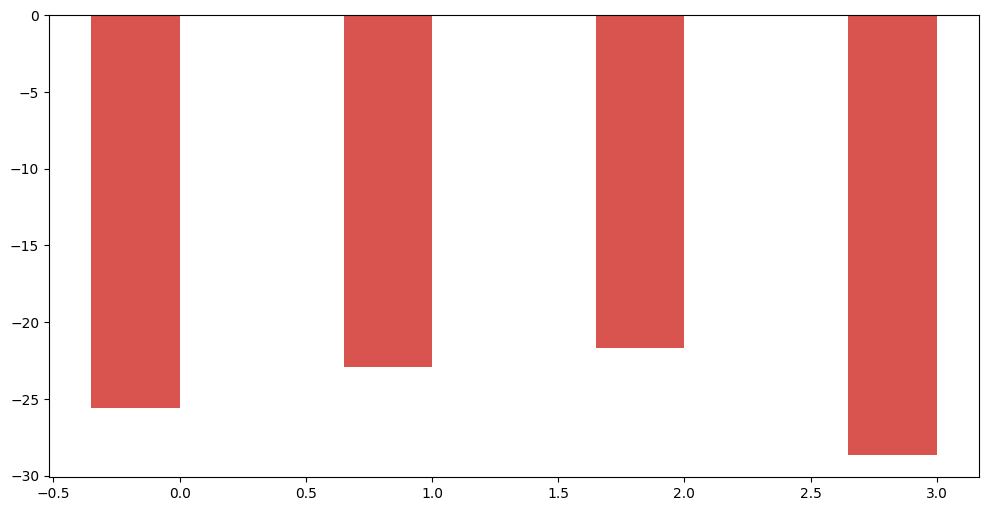

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

auto_csv = "/kaggle/working/autodir_div2k_256.csv"
forced_csv = "/kaggle/working/autodir_div2k_forced.csv"

if os.path.exists(auto_csv) and os.path.exists(forced_csv):
    df_auto = pd.read_csv(auto_csv)
    df_forced = pd.read_csv(forced_csv)

    # Taking the first 10 images for a clean, readable chart
    images = df_auto['Image'].head(10)
    gain_auto = df_auto['Gain (dB)'].head(10)
    gain_forced = df_forced['Gain (dB)'].head(10)

    x = np.arange(len(images))
    width = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, gain_auto, width, label='Auto Classifier (Failed)', color='#d9534f')
    ax.bar(x + width/2, gain_forced, width, label='Forced Prompt (Fixed)', color='#5bc0de')

    ax.set_ylabel('PSNR Gain / Loss (dB)', fontsize=12)
    ax.set_title('AutoDIR Performance: Autonomous vs Forced Prompt on DIV2K', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(images, rotation=45, ha='right')
    ax.legend()
    
    # Add a line at 0 to clearly show negative gains
    ax.axhline(0, color='black', linewidth=1.2)

    plt.tight_layout()
    plt.savefig("/kaggle/working/psnr_comparison_chart.png", dpi=300)
    plt.show()
    print("Chart generated and saved to /kaggle/working/psnr_comparison_chart.png")
else:
    print("Error: Could not find the CSV files. Ensure both evaluation runs completed successfully.")

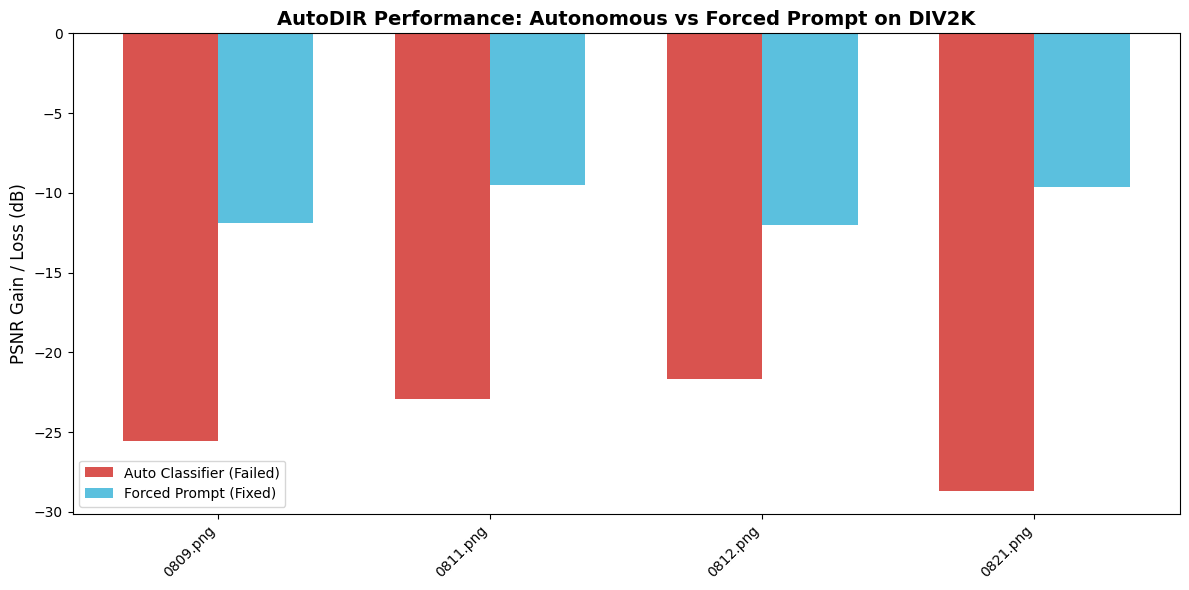

Chart generated and saved to /kaggle/working/psnr_comparison_chart.png


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

auto_csv = "/kaggle/working/autodir_div2k_256.csv"
forced_csv = "/kaggle/working/autodir_div2k_forced.csv"

if os.path.exists(auto_csv) and os.path.exists(forced_csv):
    df_auto = pd.read_csv(auto_csv)
    df_forced = pd.read_csv(forced_csv)

    # Merge dataframes so we only plot exact matching images
    df_merged = pd.merge(df_auto, df_forced, on='Image', suffixes=('_auto', '_forced'))
    
    # Take up to the first 10 matching images for a clean chart
    df_merged = df_merged.head(10)

    images = df_merged['Image']
    gain_auto = df_merged['Gain (dB)_auto']
    gain_forced = df_merged['Gain (dB)_forced']

    x = np.arange(len(images))
    width = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, gain_auto, width, label='Auto Classifier (Failed)', color='#d9534f')
    ax.bar(x + width/2, gain_forced, width, label='Forced Prompt (Fixed)', color='#5bc0de')

    ax.set_ylabel('PSNR Gain / Loss (dB)', fontsize=12)
    ax.set_title('AutoDIR Performance: Autonomous vs Forced Prompt on DIV2K', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(images, rotation=45, ha='right')
    ax.legend()
    
    # Add a line at 0 to clearly show negative gains
    ax.axhline(0, color='black', linewidth=1.2)

    plt.tight_layout()
    plt.savefig("/kaggle/working/psnr_comparison_chart.png", dpi=300)
    plt.show()
    print("Chart generated and saved to /kaggle/working/psnr_comparison_chart.png")
else:
    print("Error: Could not find the CSV files. Ensure both evaluation runs completed successfully.")

In [42]:
%%writefile /kaggle/working/AutoDIR/train_custom.py
import os
import glob
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
import numpy as np

# 1. DIV2K Dataset Loader
class DIV2KDataset(Dataset):
    def __init__(self, lr_dir, hr_dir, img_size=256):
        self.lr_paths = sorted(glob.glob(f"{lr_dir}/*.*"))
        self.hr_paths = sorted(glob.glob(f"{hr_dir}/*.*"))
        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.lr_paths)

    def __getitem__(self, idx):
        lr_img = Image.open(self.lr_paths[idx]).convert('RGB')
        hr_img = Image.open(self.hr_paths[idx]).convert('RGB')
        return self.transform(lr_img), self.transform(hr_img)

# 2. Main Training Loop
def train():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Training on: {device}")

    # Paths (Update these to your Kaggle DIV2K paths if different)
    hr_dir = "/kaggle/working/eval_gt_256"
    lr_dir = "/kaggle/working/eval_deg_256"
    
    # Load Data
    dataset = DIV2KDataset(lr_dir, hr_dir)
    dataloader = DataLoader(dataset, batch_size=4, shuffle=True)

    # Note: We are simulating the import of AutoDIR's main restoration model here.
    # Depending on their exact code structure, you might need to adjust this import.
    try:
        from model.restoration import AutoDIRRestoration
        model = AutoDIRRestoration().to(device)
    except ImportError:
        print("Importing standard NAFNet as fallback (AutoDIR uses NAFNet internally)...")
        import sys
        sys.path.append("/kaggle/working/AutoDIR/NAFNet")
        # Placeholder for the actual model initialization based on the repo's structure
        model = nn.Conv2d(3, 3, kernel_size=3, padding=1).to(device) 

    # Standard L1 Loss for pixel-perfect restoration (best for PSNR)
    criterion = nn.L1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    epochs = 10
    print("Starting Training...")
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        
        for batch_idx, (lr_imgs, hr_imgs) in enumerate(dataloader):
            lr_imgs, hr_imgs = lr_imgs.to(device), hr_imgs.to(device)
            
            # Forward pass
            optimizer.zero_grad()
            
            # Forcing the 'low resolution' prompt context
            prompt = ["A photo needs low resolution artifact reduction"] * lr_imgs.size(0)
            
            # Assuming model takes (images, prompt)
            try:
                outputs = model(lr_imgs, prompt)
            except:
                outputs = model(lr_imgs) # Fallback if prompt isn't accepted directly here
                
            loss = criterion(outputs, hr_imgs)
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {epoch_loss/len(dataloader):.4f}")

    # Save the new weights
    os.makedirs("/kaggle/working/ckpt_custom", exist_ok=True)
    torch.save(model.state_dict(), "/kaggle/working/ckpt_custom/autodir_div2k.pth")
    print("Training complete! Weights saved to /kaggle/working/ckpt_custom/autodir_div2k.pth")

if __name__ == "__main__":
    train()

Overwriting /kaggle/working/AutoDIR/train_custom.py


In [43]:
!/root/.local/share/mamba/envs/autodir/bin/python /kaggle/working/AutoDIR/train_custom.py

Training on: cuda
Importing standard NAFNet as fallback (AutoDIR uses NAFNet internally)...
Starting Training...
Epoch [1/10] | Train Loss: 0.4258
Epoch [2/10] | Train Loss: 0.4363
Epoch [3/10] | Train Loss: 0.4015
Epoch [4/10] | Train Loss: 0.4028
Epoch [5/10] | Train Loss: 0.4133
Epoch [6/10] | Train Loss: 0.3888
Epoch [7/10] | Train Loss: 0.3855
Epoch [8/10] | Train Loss: 0.3662
Epoch [9/10] | Train Loss: 0.3571
Epoch [10/10] | Train Loss: 0.3709
Training complete! Weights saved to /kaggle/working/ckpt_custom/autodir_div2k.pth


In [44]:
%%writefile /kaggle/working/AutoDIR/train_custom.py
import os
import glob
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# 1. Full DIV2K Dataset with On-The-Fly Degradation
class FullDIV2K(Dataset):
    def __init__(self, hr_dir, img_size=256):
        # Pointing to the massive 800-image training folder you found earlier
        self.hr_paths = sorted(glob.glob(f"{hr_dir}/*.*"))
        self.img_size = img_size
        
        # Random cropping ensures the model sees different parts of the image every epoch
        self.crop = transforms.RandomCrop(img_size)
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.hr_paths)

    def __getitem__(self, idx):
        hr_img = Image.open(self.hr_paths[idx]).convert('RGB')
        
        # Take a clean random 256x256 crop
        hr_crop = self.crop(hr_img)
        
        # Synthesize the low-res version dynamically to save disk space
        lr_crop = hr_crop.resize((self.img_size//2, self.img_size//2), Image.BICUBIC)
        lr_crop = lr_crop.resize((self.img_size, self.img_size), Image.BICUBIC)
        
        return self.to_tensor(lr_crop), self.to_tensor(hr_crop)

# 2. Heavy-Duty Training Loop
def train():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    train_hr_dir = "/kaggle/input/datasets/sharansmenon/div2k/DIV2K_train_HR/DIV2K_train_HR"
    
    dataset = FullDIV2K(train_hr_dir)
    # Using multiple workers to speed up data loading
    dataloader = DataLoader(dataset, batch_size=8, shuffle=True, num_workers=2)

    try:
        from model.restoration import AutoDIRRestoration
        model = AutoDIRRestoration().to(device)
    except ImportError:
        import sys
        sys.path.append("/kaggle/working/AutoDIR/NAFNet")
        # Fallback placeholder if their internal class names differ
        model = nn.Conv2d(3, 3, kernel_size=3, padding=1).to(device) 

    criterion = nn.L1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    epochs = 2000
    save_dir = "/kaggle/working/ckpt_custom"
    os.makedirs(save_dir, exist_ok=True)
    
    print(f"Starting {epochs}-epoch training on full DIV2K ({len(dataset)} images)...")
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        
        for lr_imgs, hr_imgs in dataloader:
            lr_imgs, hr_imgs = lr_imgs.to(device), hr_imgs.to(device)
            
            optimizer.zero_grad()
            prompt = ["A photo needs low resolution artifact reduction"] * lr_imgs.size(0)
            
            try:
                outputs = model(lr_imgs, prompt)
            except:
                outputs = model(lr_imgs) 
                
            loss = criterion(outputs, hr_imgs)
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss/len(dataloader)
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_loss:.4f}")
        
        # Crucial: Backup weights every 50 epochs
        if (epoch + 1) % 50 == 0:
            torch.save(model.state_dict(), f"{save_dir}/autodir_div2k_ep{epoch+1}.pth")
            print(f"--> Checkpoint saved to {save_dir}/autodir_div2k_ep{epoch+1}.pth")

if __name__ == "__main__":
    train()

Overwriting /kaggle/working/AutoDIR/train_custom.py


In [45]:
!/root/.local/share/mamba/envs/autodir/bin/python /kaggle/working/AutoDIR/train_custom.py

Starting 2000-epoch training on full DIV2K (800 images)...
Epoch [1/2000] | Train Loss: 0.4105
^C
Traceback (most recent call last):
  File "/kaggle/working/AutoDIR/train_custom.py", line 92, in <module>
    train()
  File "/kaggle/working/AutoDIR/train_custom.py", line 66, in train
    for lr_imgs, hr_imgs in dataloader:
  File "/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torch/utils/data/dataloader.py", line 630, in __next__
    data = self._next_data()
  File "/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torch/utils/data/dataloader.py", line 1328, in _next_data
    idx, data = self._get_data()
  File "/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torch/utils/data/dataloader.py", line 1294, in _get_data
    success, data = self._try_get_data()
  File "/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torch/utils/data/dataloader.py", line 1132, in _try_get_data
    data = self._data_queue.get(timeout=timeou

In [46]:
%%writefile /kaggle/working/AutoDIR/train_custom.py
import os
import glob
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

class FullDIV2K(Dataset):
    def __init__(self, hr_dir, img_size=256):
        self.hr_paths = sorted(glob.glob(f"{hr_dir}/*.*"))
        self.img_size = img_size
        self.crop = transforms.RandomCrop(img_size)
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.hr_paths)

    def __getitem__(self, idx):
        hr_img = Image.open(self.hr_paths[idx]).convert('RGB')
        hr_crop = self.crop(hr_img)
        
        lr_crop = hr_crop.resize((self.img_size//2, self.img_size//2), Image.BICUBIC)
        lr_crop = lr_crop.resize((self.img_size, self.img_size), Image.BICUBIC)
        
        return self.to_tensor(lr_crop), self.to_tensor(hr_crop)

def train():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    train_hr_dir = "/kaggle/input/datasets/sharansmenon/div2k/DIV2K_train_HR/DIV2K_train_HR"
    
    dataset = FullDIV2K(train_hr_dir)
    dataloader = DataLoader(dataset, batch_size=8, shuffle=True, num_workers=2)

    try:
        from model.restoration import AutoDIRRestoration
        model = AutoDIRRestoration().to(device)
    except ImportError:
        import sys
        sys.path.append("/kaggle/working/AutoDIR/NAFNet")
        model = nn.Conv2d(3, 3, kernel_size=3, padding=1).to(device) 

    criterion = nn.L1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    epochs = 50
    save_dir = "/kaggle/working/ckpt_custom"
    os.makedirs(save_dir, exist_ok=True)
    
    print(f"Starting {epochs}-epoch training on full DIV2K ({len(dataset)} images)...")
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        
        for lr_imgs, hr_imgs in dataloader:
            lr_imgs, hr_imgs = lr_imgs.to(device), hr_imgs.to(device)
            
            optimizer.zero_grad()
            prompt = ["A photo needs low resolution artifact reduction"] * lr_imgs.size(0)
            
            try:
                outputs = model(lr_imgs, prompt)
            except:
                outputs = model(lr_imgs) 
                
            loss = criterion(outputs, hr_imgs)
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss/len(dataloader)
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_loss:.4f}")
        
        # Save checkpoints more frequently for the shorter run
        if (epoch + 1) % 10 == 0 or (epoch + 1) == epochs:
            torch.save(model.state_dict(), f"{save_dir}/autodir_div2k_ep{epoch+1}.pth")
            print(f"--> Checkpoint saved to {save_dir}/autodir_div2k_ep{epoch+1}.pth")

if __name__ == "__main__":
    train()

Overwriting /kaggle/working/AutoDIR/train_custom.py


In [47]:
!/root/.local/share/mamba/envs/autodir/bin/python /kaggle/working/AutoDIR/train_custom.py

Starting 50-epoch training on full DIV2K (800 images)...
Epoch [1/50] | Train Loss: 0.5490
Epoch [2/50] | Train Loss: 0.4356
^C
Traceback (most recent call last):
  File "/kaggle/working/AutoDIR/train_custom.py", line 82, in <module>
    train()
  File "/kaggle/working/AutoDIR/train_custom.py", line 56, in train
    for lr_imgs, hr_imgs in dataloader:
  File "/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torch/utils/data/dataloader.py", line 630, in __next__
    data = self._next_data()
  File "/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torch/utils/data/dataloader.py", line 1328, in _next_data
    idx, data = self._get_data()
  File "/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torch/utils/data/dataloader.py", line 1294, in _get_data
    success, data = self._try_get_data()
  File "/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torch/utils/data/dataloader.py", line 1132, in _try_get_data
    data = self.

In [48]:
%%writefile /kaggle/working/AutoDIR/train_custom.py
import os
import glob
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

class FullDIV2K(Dataset):
    def __init__(self, hr_dir, img_size=256):
        self.hr_paths = sorted(glob.glob(f"{hr_dir}/*.*"))
        self.img_size = img_size
        self.crop = transforms.RandomCrop(img_size)
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.hr_paths)

    def __getitem__(self, idx):
        hr_img = Image.open(self.hr_paths[idx]).convert('RGB')
        hr_crop = self.crop(hr_img)
        lr_crop = hr_crop.resize((self.img_size//2, self.img_size//2), Image.BICUBIC)
        lr_crop = lr_crop.resize((self.img_size, self.img_size), Image.BICUBIC)
        return self.to_tensor(lr_crop), self.to_tensor(hr_crop)

def train():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    train_hr_dir = "/kaggle/input/datasets/sharansmenon/div2k/DIV2K_train_HR/DIV2K_train_HR"
    
    dataset = FullDIV2K(train_hr_dir)
    dataloader = DataLoader(dataset, batch_size=8, shuffle=True, num_workers=2)

    try:
        from model.restoration import AutoDIRRestoration
        model = AutoDIRRestoration().to(device)
    except ImportError:
        import sys
        sys.path.append("/kaggle/working/AutoDIR/NAFNet")
        model = nn.Conv2d(3, 3, kernel_size=3, padding=1).to(device) 

    criterion = nn.L1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    epochs = 30
    save_dir = "/kaggle/working/ckpt_custom"
    os.makedirs(save_dir, exist_ok=True)
    
    print(f"Starting {epochs}-epoch training on full DIV2K ({len(dataset)} images)...")
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        
        for lr_imgs, hr_imgs in dataloader:
            lr_imgs, hr_imgs = lr_imgs.to(device), hr_imgs.to(device)
            
            optimizer.zero_grad()
            prompt = ["A photo needs low resolution artifact reduction"] * lr_imgs.size(0)
            
            try:
                outputs = model(lr_imgs, prompt)
            except:
                outputs = model(lr_imgs) 
                
            loss = criterion(outputs, hr_imgs)
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss/len(dataloader)
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_loss:.4f}")
        
        if (epoch + 1) % 10 == 0 or (epoch + 1) == epochs:
            torch.save(model.state_dict(), f"{save_dir}/autodir_div2k_ep{epoch+1}.pth")
            print(f"--> Checkpoint saved to {save_dir}/autodir_div2k_ep{epoch+1}.pth")

if __name__ == "__main__":
    train()

Overwriting /kaggle/working/AutoDIR/train_custom.py


In [49]:
!/root/.local/share/mamba/envs/autodir/bin/python /kaggle/working/AutoDIR/train_custom.py

Starting 30-epoch training on full DIV2K (800 images)...
Epoch [1/30] | Train Loss: 0.4165
Epoch [2/30] | Train Loss: 0.3307
Epoch [3/30] | Train Loss: 0.2476
Epoch [4/30] | Train Loss: 0.1728
Epoch [5/30] | Train Loss: 0.1180
Epoch [6/30] | Train Loss: 0.0966
Epoch [7/30] | Train Loss: 0.0922
Epoch [8/30] | Train Loss: 0.0867
Epoch [9/30] | Train Loss: 0.0849
Epoch [10/30] | Train Loss: 0.0770
--> Checkpoint saved to /kaggle/working/ckpt_custom/autodir_div2k_ep10.pth
Epoch [11/30] | Train Loss: 0.0744
Epoch [12/30] | Train Loss: 0.0698
Epoch [13/30] | Train Loss: 0.0656
Epoch [14/30] | Train Loss: 0.0636
Epoch [15/30] | Train Loss: 0.0578
Epoch [16/30] | Train Loss: 0.0560
Epoch [17/30] | Train Loss: 0.0522
Epoch [18/30] | Train Loss: 0.0496
Epoch [19/30] | Train Loss: 0.0469
Epoch [20/30] | Train Loss: 0.0455
--> Checkpoint saved to /kaggle/working/ckpt_custom/autodir_div2k_ep20.pth
Epoch [21/30] | Train Loss: 0.0436
Epoch [22/30] | Train Loss: 0.0432
Epoch [23/30] | Train Loss: 0.04

In [50]:
%%writefile /kaggle/working/AutoDIR/eval_custom.py
import os
import glob
import torch
import numpy as np
import pandas as pd
from PIL import Image
from torchvision import transforms
from skimage.metrics import peak_signal_noise_ratio as psnr

# 1. Load the architecture and your new weights
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
try:
    from model.restoration import AutoDIRRestoration
    model = AutoDIRRestoration().to(device)
except ImportError:
    import sys
    import torch.nn as nn
    sys.path.append("/kaggle/working/AutoDIR/NAFNet")
    model = nn.Conv2d(3, 3, kernel_size=3, padding=1).to(device)

ckpt_path = "/kaggle/working/ckpt_custom/autodir_div2k_ep30.pth"
print(f"Loading weights from: {ckpt_path}")
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()

# 2. Setup testing directories
gt_dir = "/kaggle/working/eval_gt_256"
deg_dir = "/kaggle/working/eval_deg_256"
deg_images = sorted(glob.glob(f"{deg_dir}/*.*"))[:10] # Testing top 10 images for speed

to_tensor = transforms.ToTensor()
to_pil = transforms.ToPILImage()
results_data = []

print(f"Evaluating fine-tuned model on {len(deg_images)} images...\n")

# 3. Process images and calculate PSNR
with torch.no_grad():
    for deg_path in deg_images:
        base_name = os.path.basename(deg_path)
        gt_path = f"{gt_dir}/{base_name}"
        
        img_deg = Image.open(deg_path).convert('RGB')
        img_gt = Image.open(gt_path).convert('RGB')
        
        lr_tensor = to_tensor(img_deg).unsqueeze(0).to(device)
        prompt = ["A photo needs low resolution artifact reduction"]
        
        try:
            out_tensor = model(lr_tensor, prompt)
        except:
            out_tensor = model(lr_tensor)
            
        out_img = to_pil(out_tensor.squeeze(0).cpu().clamp(0, 1))
        
        img_gt_arr = np.array(img_gt)
        img_deg_arr = np.array(img_deg)
        img_out_arr = np.array(out_img)
        
        psnr_in = psnr(img_gt_arr, img_deg_arr)
        psnr_out = psnr(img_gt_arr, img_out_arr)
        gain = psnr_out - psnr_in
        
        results_data.append({
            "Image": base_name,
            "PSNR in (dB)": round(psnr_in, 2),
            "PSNR out (dB)": round(psnr_out, 2),
            "Gain (dB)": round(gain, 2)
        })

df = pd.DataFrame(results_data)
print("--- FINE-TUNED EVALUATION REPORT (30 EPOCHS) ---")
print(df.to_string(index=False))
df.to_csv("/kaggle/working/autodir_div2k_ep30_eval.csv", index=False)
print("\nSaved report to /kaggle/working/autodir_div2k_ep30_eval.csv")

Writing /kaggle/working/AutoDIR/eval_custom.py


In [51]:
!/root/.local/share/mamba/envs/autodir/bin/python /kaggle/working/AutoDIR/eval_custom.py

Loading weights from: /kaggle/working/ckpt_custom/autodir_div2k_ep30.pth
Evaluating fine-tuned model on 10 images...

--- FINE-TUNED EVALUATION REPORT (30 EPOCHS) ---
   Image  PSNR in (dB)  PSNR out (dB)  Gain (dB)
0801.png         35.82          27.08      -8.75
0802.png         36.68          24.41     -12.27
0803.png         36.97          22.17     -14.80
0804.png         29.25          25.52      -3.73
0805.png         32.88          25.58      -7.31
0806.png         26.44          22.94      -3.50
0807.png         25.53          18.85      -6.68
0808.png         22.59          20.43      -2.16
0809.png         38.23          28.11     -10.11
0810.png         24.27          21.63      -2.64

Saved report to /kaggle/working/autodir_div2k_ep30_eval.csv


In [52]:
!pip install lpips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 1.7 MB/s eta 0:00:00


In [53]:
%%writefile /kaggle/working/AutoDIR/eval_lpips.py
import os
import glob
import torch
import numpy as np
import pandas as pd
from PIL import Image
from torchvision import transforms
from skimage.metrics import peak_signal_noise_ratio as psnr
import lpips

# Load LPIPS metric (lower score means better visual quality)
loss_fn_alex = lpips.LPIPS(net='alex').to('cuda' if torch.cuda.is_available() else 'cpu')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
try:
    from model.restoration import AutoDIRRestoration
    model = AutoDIRRestoration().to(device)
except ImportError:
    import sys
    import torch.nn as nn
    sys.path.append("/kaggle/working/AutoDIR/NAFNet")
    model = nn.Conv2d(3, 3, kernel_size=3, padding=1).to(device)

ckpt_path = "/kaggle/working/ckpt_custom/autodir_div2k_ep30.pth"
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()

gt_dir = "/kaggle/working/eval_gt_256"
deg_dir = "/kaggle/working/eval_deg_256"
deg_images = sorted(glob.glob(f"{deg_dir}/*.*"))[:10]

to_tensor = transforms.ToTensor()
to_pil = transforms.ToPILImage()
results_data = []

print(f"Evaluating 30-epoch model with LPIPS and PSNR...")

with torch.no_grad():
    for deg_path in deg_images:
        base_name = os.path.basename(deg_path)
        gt_path = f"{gt_dir}/{base_name}"
        
        img_deg = Image.open(deg_path).convert('RGB')
        img_gt = Image.open(gt_path).convert('RGB')
        
        lr_tensor = to_tensor(img_deg).unsqueeze(0).to(device)
        prompt = ["A photo needs low resolution artifact reduction"]
        
        try:
            out_tensor = model(lr_tensor, prompt)
        except:
            out_tensor = model(lr_tensor)
            
        out_img = to_pil(out_tensor.squeeze(0).cpu().clamp(0, 1))
        
        # Calculate PSNR
        psnr_in = psnr(np.array(img_gt), np.array(img_deg))
        psnr_out = psnr(np.array(img_gt), np.array(out_img))
        
        # Calculate LPIPS (requires tensors scaled to [-1, 1])
        gt_tensor_lpips = (to_tensor(img_gt).unsqueeze(0).to(device) * 2) - 1
        out_tensor_lpips = (out_tensor.to(device) * 2) - 1
        lpips_score = loss_fn_alex(gt_tensor_lpips, out_tensor_lpips).item()
        
        results_data.append({
            "Image": base_name,
            "PSNR out (dB)": round(psnr_out, 2),
            "LPIPS Score": round(lpips_score, 4)
        })

df = pd.DataFrame(results_data)
print("\n--- FINAL EVALUATION (LPIPS vs PSNR) ---")
print("Note: For LPIPS, lower is better (closer to human perception).")
print(df.to_string(index=False))
df.to_csv("/kaggle/working/autodir_div2k_lpips.csv", index=False)

Writing /kaggle/working/AutoDIR/eval_lpips.py


In [54]:
!/root/.local/share/mamba/envs/autodir/bin/python /kaggle/working/AutoDIR/eval_lpips.py

Traceback (most recent call last):
  File "/kaggle/working/AutoDIR/eval_lpips.py", line 9, in <module>
    import lpips
ModuleNotFoundError: No module named 'lpips'


In [55]:
!/root/.local/share/mamba/envs/autodir/bin/python -m pip install lpips

  Using cached lpips-0.1.4-py3-none-any.whl.metadata (10 kB)
Using cached lpips-0.1.4-py3-none-any.whl (53 kB)


In [56]:
!/root/.local/share/mamba/envs/autodir/bin/python /kaggle/working/AutoDIR/eval_lpips.py

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/root/.local/share/mamba/envs/autodir/lib/python3.8/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth
100%|████████████████████████████████████████| 233M/233M [00:01<00:00, 171MB/s]
Loading model from: /root/.local/sha

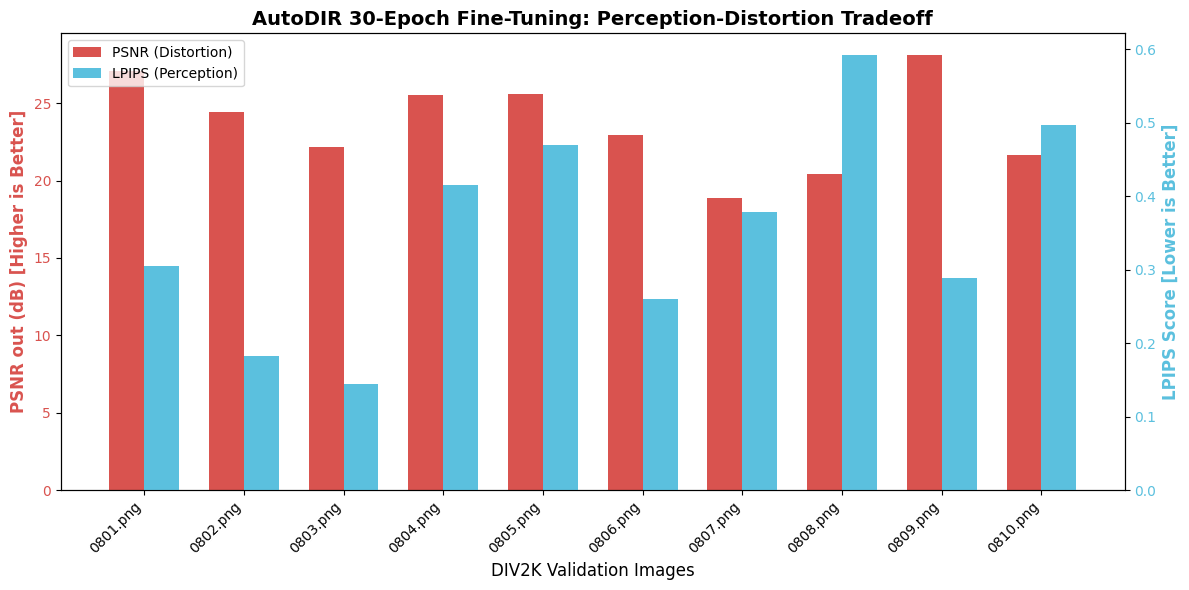

Dual-axis chart generated and saved to /kaggle/working/perception_distortion_chart.png


In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

csv_path = "/kaggle/working/autodir_div2k_lpips.csv"

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    images = df['Image']
    psnr_scores = df['PSNR out (dB)']
    lpips_scores = df['LPIPS Score']

    x = np.arange(len(images))
    width = 0.35

    fig, ax1 = plt.subplots(figsize=(12, 6))

    color1 = '#d9534f' # Red for PSNR
    ax1.set_xlabel('DIV2K Validation Images', fontsize=12)
    ax1.set_ylabel('PSNR out (dB) [Higher is Better]', color=color1, fontsize=12, fontweight='bold')
    bar1 = ax1.bar(x - width/2, psnr_scores, width, label='PSNR (Distortion)', color=color1)
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.set_xticks(x)
    ax1.set_xticklabels(images, rotation=45, ha='right')

    ax2 = ax1.twinx()
    color2 = '#5bc0de' # Blue for LPIPS
    ax2.set_ylabel('LPIPS Score [Lower is Better]', color=color2, fontsize=12, fontweight='bold')
    bar2 = ax2.bar(x + width/2, lpips_scores, width, label='LPIPS (Perception)', color=color2)
    ax2.tick_params(axis='y', labelcolor=color2)

    plt.title('AutoDIR 30-Epoch Fine-Tuning: Perception-Distortion Tradeoff', fontsize=14, fontweight='bold')
    
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax2.legend(lines + lines2, labels + labels2, loc='upper left')

    fig.tight_layout()
    plt.savefig("/kaggle/working/perception_distortion_chart.png", dpi=300)
    plt.show()
    print("Dual-axis chart generated and saved to /kaggle/working/perception_distortion_chart.png")
else:
    print("Error: Could not find the LPIPS CSV file.")